# Pixel geometry in chemical label space

This notebook represents every pixel through the chemical label graph — as class abundances and as graph-propagated label signatures — and compares the resulting segmentations with segmentations of the original ion composition. It answers how much spatial structure survives when spectra are expressed through graph labels, how this depends on the graph variant and on the number of propagation steps, and therefore how label embeddings should be fitted so that they support rather than flatten the latent representation used for segmentation.

## Introduction

In an ML-GCN-type head the score of label $j$ for latent $z$ is $s_j = e_j^\top P z$, where $e_j$ is the graph-generated embedding of label $j$. Training aligns $z$ with the label embeddings of the ions present in the spectrum, so the geometry that the encoder is pushed towards is approximately that of $\sum_m \tilde x_{pm}\, e_m$. With one-hot initial features and $k$ linear propagation steps, $e_m$ is row $m$ of $\hat A^k$ — the *graph-$k$ signature* used here as a model-free proxy. Three pixel representations are compared:

- **ions** — TIC-normalized annotated ion composition $\tilde x_p$ (reference);
- **classes** — class abundances $s_p = W^\top \tilde x_p$;
- **graph-$k$** — $\tilde x_p^\top \hat A^k_{M\cdot}$ for $k \in \{1, 2\}$.

### Assumptions

- **Proxy, not a trained model.** The analysis characterizes the geometry that the label graph would impose; it does not train an encoder. Learned relation weights can deviate from the linear propagation.
- **Segmentation by k-means.** $k=6$ clusters per image, fitted on a seeded sample of at most 4000 pixels and applied to all pixels; k-means is a reference partitioner, not the planned latent-space clustering (Leiden/HDBSCAN).
- **Distance-preserving factorization.** Label-space representations are computed through $L$ with $LL^\top = EE^\top$, which preserves all Euclidean pixel distances while keeping the dimension equal to the number of ions in the image.
- **Resolved ions only.** Only ions with at least one retained class of the variant enter every representation, including the ion-space reference; an unresolved ion would otherwise disappear from the class representation but keep its one-hot identity in graph-$k$, inflating graph-$k$ agreement. The ion-space reference therefore differs between variants, and images with fewer than two resolved ions are skipped.

### Notation

- $\mathrm{ARI}$ — adjusted Rand index between a label-space segmentation and the ion-space segmentation of the same image (1 = identical, 0 = chance).
- Spatial coherence — fraction of 4-neighbour pixel pairs with equal cluster labels (higher = smoother segmentation).

In [1]:
from pathlib import Path

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from msi_autoencoder_wrapper.analysis.precompute.cli import run_precompute_command
from msi_autoencoder_wrapper.analysis.precompute.strategies.chemistry import class_graph_analysis as precompute
from msi_autoencoder_wrapper.visualization import chemistry as plots
from msi_autoencoder_wrapper.visualization.theme import resolve_theme

SETTINGS = precompute.read_settings(Path("analysis_settings.yaml"))
THEME = resolve_theme("diagnostic_light")
ANALYSIS = "label_space_embedding"
CONFIG = SETTINGS["analyses"][ANALYSIS]
COLLECTIONS = list(SETTINGS["collections"])
TAXONOMIES = SETTINGS["taxonomies"]["order"]
pd.set_option("display.width", 200, "display.max_columns", 40)


def table(name):
    """Load one canonical result table of this notebook's analysis."""
    return precompute.load_result(SETTINGS, ANALYSIS, name)


print("Precompute command:", run_precompute_command(SETTINGS["settings_path"], background=False), "--analysis", ANALYSIS)

2026-10-13 09:56:24,467 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 1 implementation module(s) in package 'msi_autoencoder_wrapper.binners.binners_strategies'.


2026-10-13 09:56:24,469 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 6 implementation module(s) in package 'msi_autoencoder_wrapper.binners.inverse_strategies'.


2026-10-13 09:56:24,850 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 3 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders.presets'.


2026-10-13 09:56:24,852 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 28 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.autoencoders'.


2026-10-13 09:56:24,861 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 0 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures.types.schema'.


2026-10-13 09:56:24,862 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 46 implementation module(s) in package 'msi_autoencoder_wrapper.models.architectures'.


2026-10-13 09:56:24,878 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 2 implementation module(s) in package 'msi_autoencoder_wrapper.models.datasets.strategies'.


2026-10-13 09:56:24,892 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 29 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions.autoencoder'.


2026-10-13 09:56:24,894 | INFO     | msi_autoencoder_wrapper.utils.module_search:79 | Discovered 33 implementation module(s) in package 'msi_autoencoder_wrapper.training.criterions'.


Precompute command: uv run --extra cu118 python -m msi_autoencoder_wrapper.analysis.precompute --settings /home/max/repositories/MSIAutoEncoderWrapper/assets/experiments/autoencoder_architecture/notebooks/GCN_expansion/analysis_settings.yaml --analysis label_space_embedding


## Retention of ion-space segmentation structure in label spaces

### Methodology

#### Theoretical

ARI between the k-means segmentation of a label-space representation and of the ion composition measures how much of the composition-defined tissue partition is preserved after mapping spectra to classes or propagated graph signatures. Low ARI with high spatial coherence means that the label space produces a different but spatially smooth partition (coarser chemical regions); low ARI with low coherence means that the mapping destroys spatial structure.

#### Implementation

`clustering.csv`: per image, focus variant and representation, ARI against the ion-space segmentation and the spatial coherence; k-means with `n_init = 4`, seed from settings; graph propagation on the GPU. Images whose ion count in the variant is below the number of clusters are skipped.

#### Figure descriptions

*Figure 1.* One panel per focus variant (selected collection); $x$: representation (classes, graph-1, graph-2); $y$: ARI with the ion-space segmentation; each point is one image. Higher values mean the representation preserves the composition partition.

ari_vs_ions                      spatial_coherence                       
representation                                                    classes graph_1 graph_2 ions           classes graph_1 graph_2   ions
collection variant_id                                                                                                                  
brain      CF/formula/certain/all_ancestors/align=none/add...       0.632   0.741   0.717  1.0             0.761   0.825   0.814  0.826
           CF/formula/certain/all_ancestors/align=none/add...       0.568   0.809   0.640  1.0             0.797   0.830   0.782  0.848
           CF/formula/weighted/all_ancestors/align=none/ad...       0.550   0.827   0.616  1.0             0.822   0.846   0.810  0.854
           CF/metaspace_ids/certain/all_ancestors/align=no...       0.545   0.785   0.583  1.0             0.823   0.833   0.796  0.854
           ChEBI/formula/certain/all_ancestors/align=none/...       0.446   0.605   0.465  1.0             0.752   0.843   0.800  0.855
           LM+CF/formula/certain/all_ancestors/align=decla...       0.677   0.671   0.590  1.0             0.827   0.848   0.814  0.856
           LM+SL+CF+ChEBI/formula/certain/all_ancestors/al...       0.522   0.666   0.611  1.0             0.790   0.831   0.836  0.858
           LM/formula/certain/all_ancestors/align=none/add...       0.499   0.829   0.794  1.0             0.801   0.868   0.848  0.855
           SL/formula/certain/all_ancestors/align=none/add...       0.541   0.872   0.651  1.0             0.782   0.844   0.824  0.844
kidney     CF/formula/certain/all_ancestors/align=none/add...       0.546   0.766   0.647  1.0             0.594   0.602   0.599  0.585
           CF/formula/certain/all_ancestors/align=none/add...       0.516   0.820   0.615  1.0             0.598   0.631   0.668  0.654
           CF/formula/weighted/all_ancestors/align=none/ad...       0.607   0.760   0.588  1.0             0.606   0.655   0.603  0.642
           CF/metaspace_ids/certain/all_ancestors/align=no...       0.640   0.818   0.592  1.0             0.608   0.623   0.602  0.628
           ChEBI/formula/certain/all_ancestors/align=none/...       0.565   0.655   0.444  1.0             0.648   0.602   0.592  0.631
           LM+CF/formula/certain/all_ancestors/align=decla...       0.643   0.793   0.635  1.0             0.626   0.644   0.638  0.662
           LM+SL+CF+ChEBI/formula/certain/all_ancestors/al...       0.599   0.703   0.697  1.0             0.634   0.614   0.617  0.673
           LM/formula/certain/all_ancestors/align=none/add...       0.724   0.922   0.871  1.0             0.630   0.654   0.665  0.638
           SL/formula/certain/all_ancestors/align=none/add...       0.713   0.918   0.798  1.0             0.663   0.662   0.651  0.652

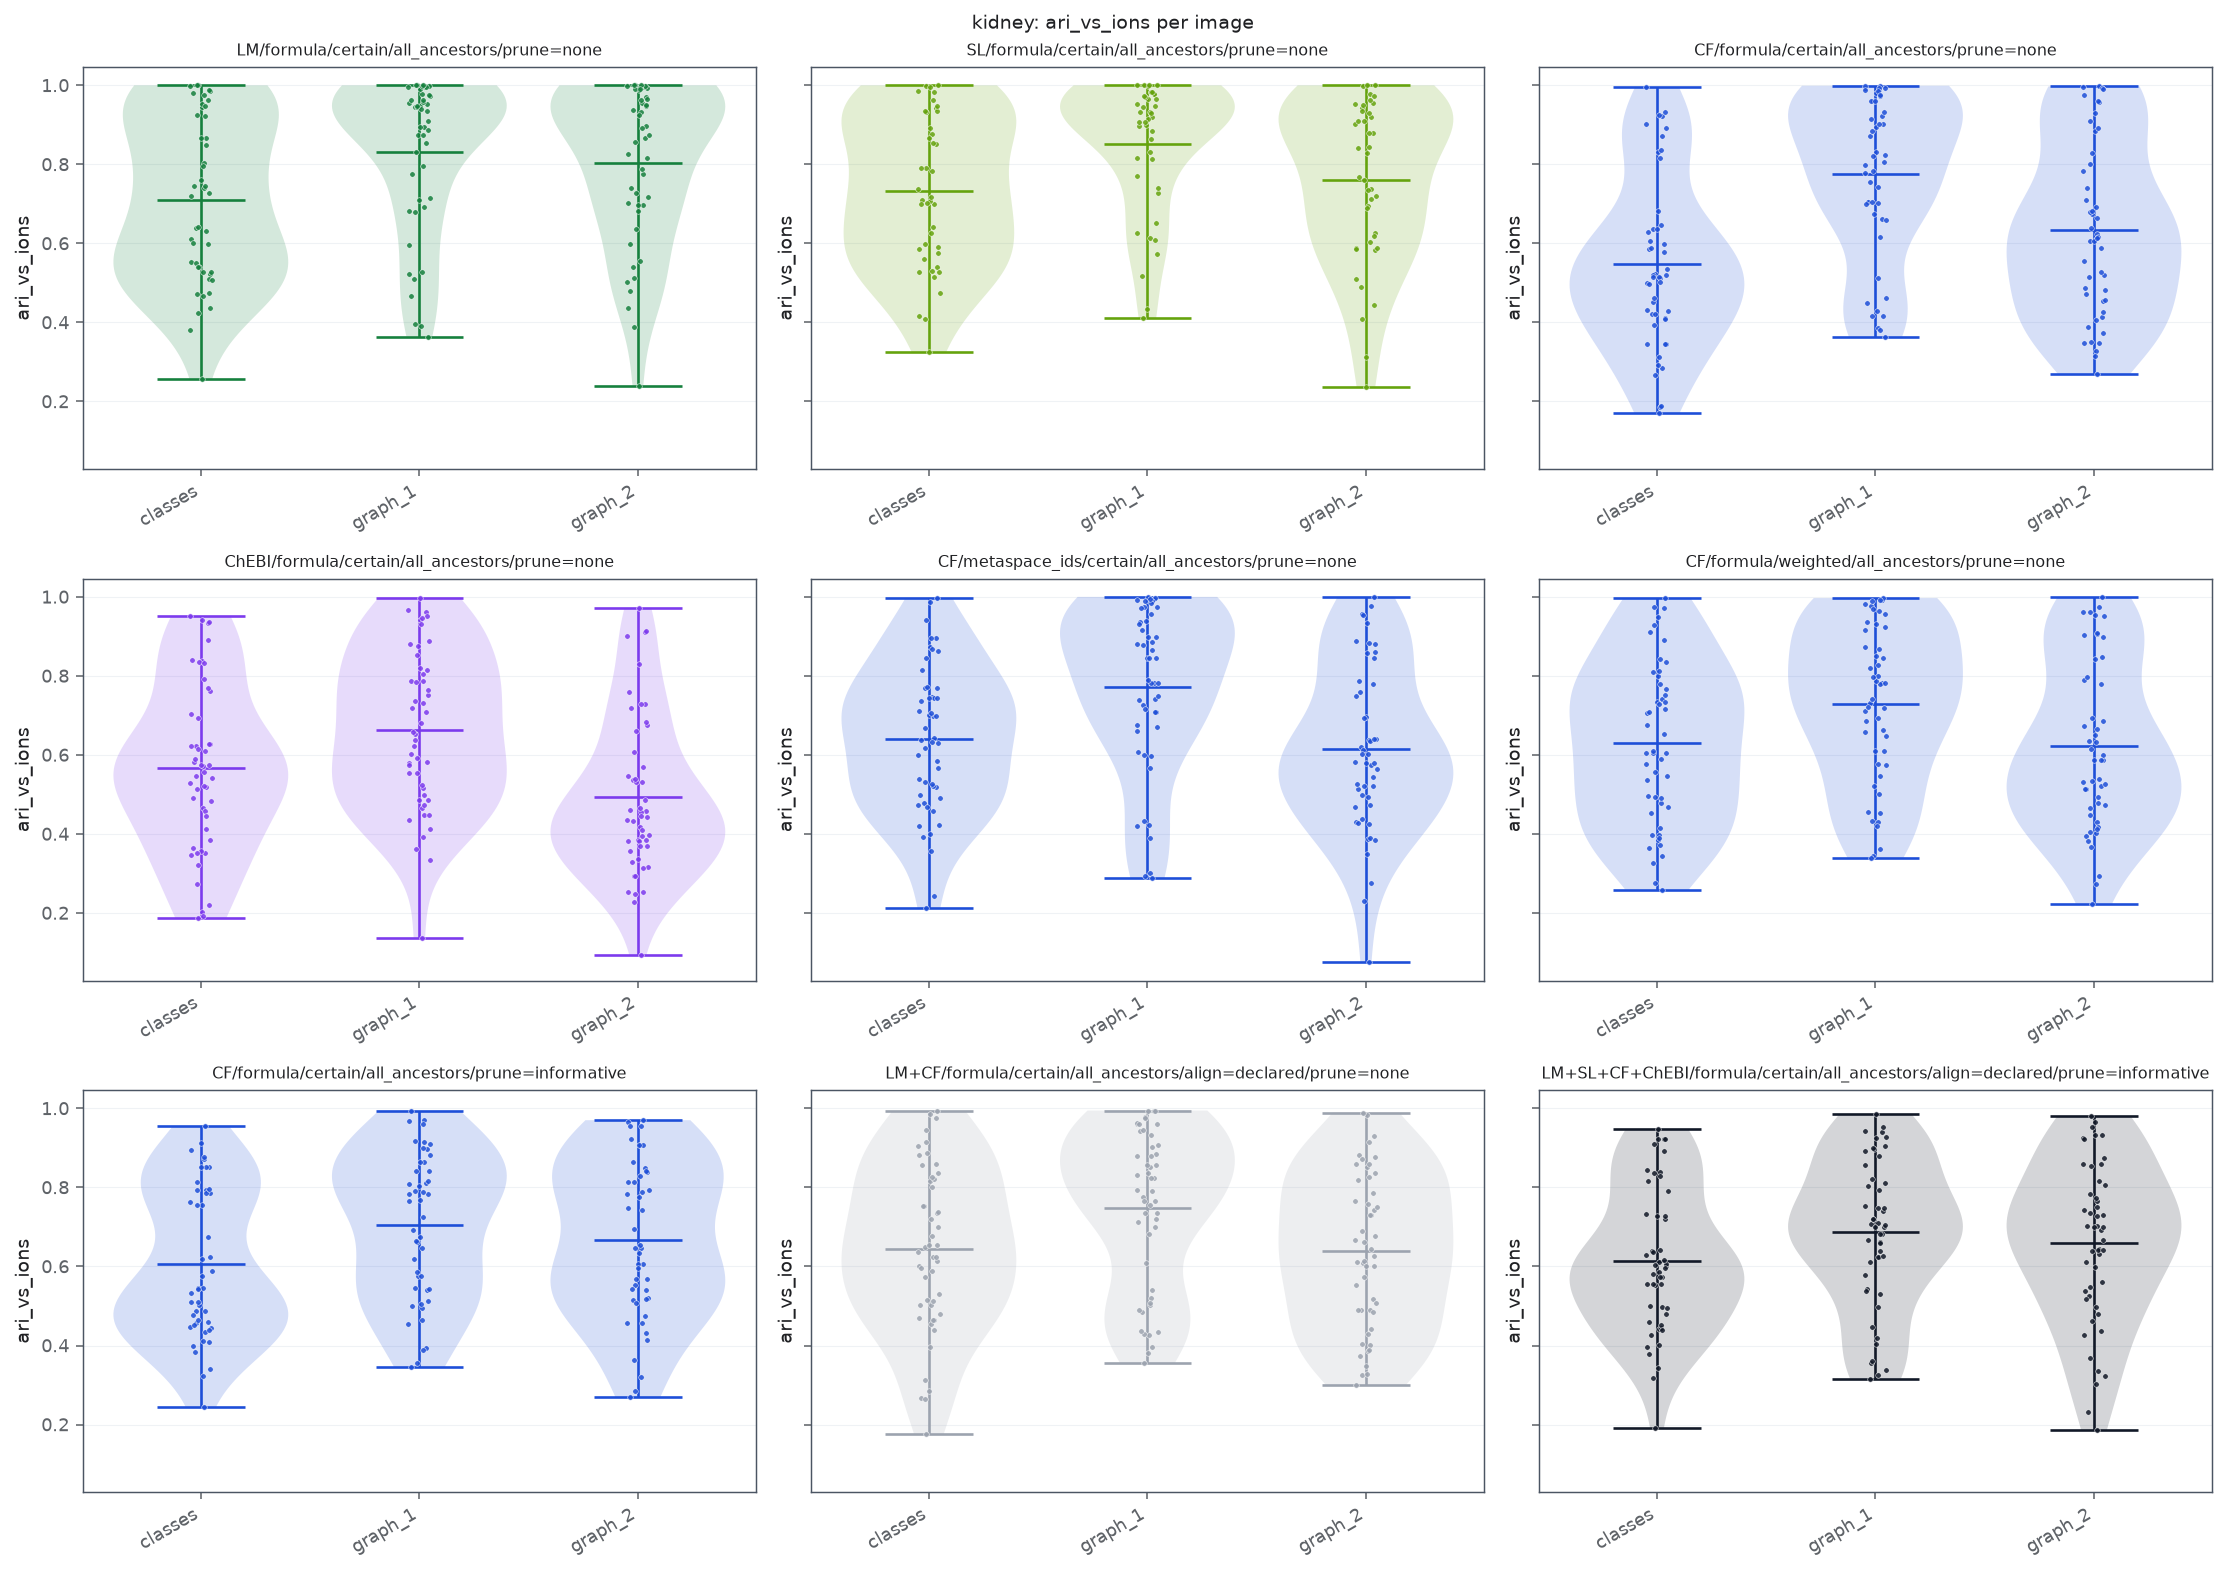

In [2]:
clustering = table("clustering.csv")
label_spaces = ["classes", "graph_1", "graph_2"]

# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
METRIC = "ari_vs_ions"      # ari_vs_ions | spatial_coherence
# ---------------------------------------------------------------------------
subset = clustering[(clustering.collection == COLLECTION) & clustering.representation.isin(label_spaces)]
variants = list(dict.fromkeys(subset.variant_id))
columns = 3
figure, axes = plt.subplots(int(np.ceil(len(variants) / columns)), columns, figsize=(16, 3.8 * np.ceil(len(variants) / columns)),
                            sharey=True, squeeze=False)
for axis, variant in zip(axes.ravel(), variants):
    rows = subset[subset.variant_id == variant]
    plots.violin_groups(axis, rows, group="representation", value=METRIC, order=label_spaces,
                        colors={r: plots.taxonomy_color(variant.split("/")[0]) for r in label_spaces}, theme=THEME)
    axis.set_title(variant.replace("/align=none", "").replace("/adduct=0", ""), fontsize=8)
for axis in axes.ravel()[len(variants):]:
    axis.set_axis_off()
figure.suptitle(f"{COLLECTION}: {METRIC} per image", fontsize=10)
plt.tight_layout()
display(clustering.groupby(["collection", "variant_id", "representation"])[["ari_vs_ions", "spatial_coherence"]].median().unstack("representation").round(3))

### Remarks

- Median ARI with the ion-space segmentation over all images and variants: graph-1 0.78 (kidney and brain), graph-2 0.64, class abundances 0.61 (kidney) / 0.54 (brain). The lipid taxonomies retain most structure (kidney graph-1 ARI 0.92 for LIPID MAPS and SwissLipids).
- Images enter only when the variant resolves at least two of their ions and they have at least 6 pixels (kidney 42–50, brain 23–24 images per variant); 32 k-means fits reported fewer distinct points than clusters (degenerate label spaces in images with very few resolved ions).

### Notes

## Spatial smoothness of label-space segmentations relative to ion space

### Methodology

#### Theoretical

For each image, the paired difference of spatial coherence between a label-space segmentation and the ion-space segmentation shows whether expressing pixels through the graph produces smoother (positive) or noisier (negative) partitions. Smoother partitions can be desirable for anatomical segmentation but also indicate loss of fine structure; the comparison with ARI distinguishes the two.

#### Implementation

Paired per image from `clustering.csv`: coherence(representation) − coherence(ions).

#### Figure descriptions

*Figure 2.* $x$: ARI with ion space; $y$: paired coherence difference; one point per image and representation (marker), colour = focus variant, for the selected collection. The horizontal line at 0 marks equal smoothness. Upper-left points: smoother but different partitions; lower-left: structure destroyed; right: partitions preserved.

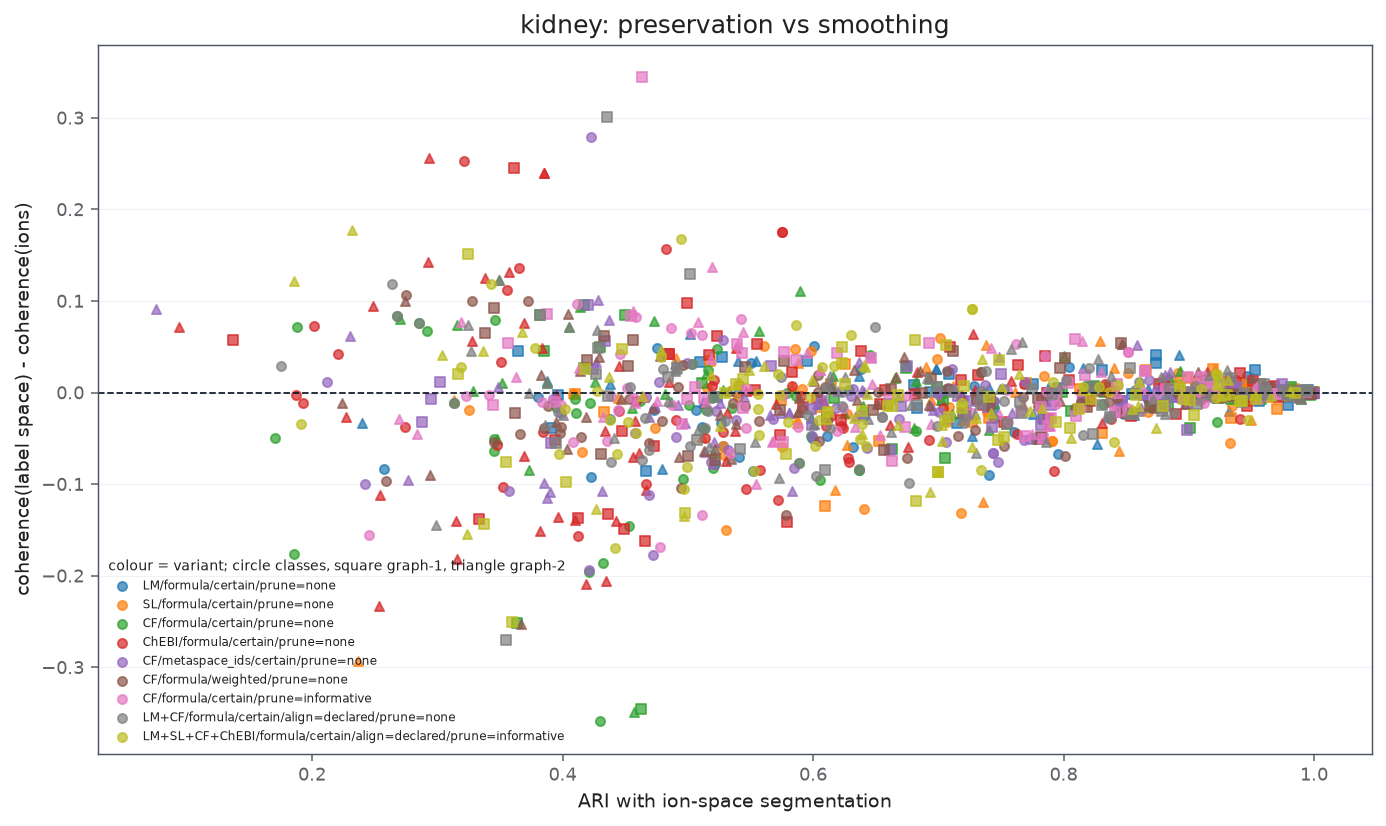

In [3]:
# --- what this figure shows -------------------------------------------------
COLLECTION = "kidney"
MARKERS = {"classes": "o", "graph_1": "s", "graph_2": "^"}
# ---------------------------------------------------------------------------
subset = clustering[clustering.collection == COLLECTION]
reference = subset[subset.representation == "ions"].set_index(["dataset_id", "variant_id"]).spatial_coherence
rows = subset[subset.representation.isin(MARKERS)].copy()
rows["coherence_gain"] = rows.spatial_coherence.to_numpy() - reference.reindex(pd.MultiIndex.from_frame(rows[["dataset_id", "variant_id"]])).to_numpy()
figure, axis = plt.subplots(figsize=(10, 6))
palette = plt.get_cmap("tab10")
short = lambda v: v.replace("/all_ancestors", "").replace("/align=none", "").replace("/adduct=0", "")
for index, variant in enumerate(dict.fromkeys(rows.variant_id)):
    for representation, marker in MARKERS.items():
        selected = rows[(rows.variant_id == variant) & (rows.representation == representation)]
        axis.scatter(selected.ari_vs_ions, selected.coherence_gain, marker=marker, s=22, alpha=0.7,
                     color=palette(index % 10), label=short(variant) if representation == "classes" else None)
axis.axhline(0, color=THEME.baseline_color, linestyle=THEME.baseline_line_style, linewidth=THEME.reference_line_width)
axis.set_xlabel("ARI with ion-space segmentation")
axis.set_ylabel("coherence(label space) - coherence(ions)")
axis.legend(fontsize=6, frameon=False, ncols=1, loc="lower left", title="colour = variant; circle classes, square graph-1, triangle graph-2", title_fontsize=7)
axis.set_title(f"{COLLECTION}: preservation vs smoothing")
plt.tight_layout()

### Remarks

- Spatial coherence of label-space segmentations is practically equal to that of ion-space segmentations (median paired difference −0.03 to 0.00); the label spaces do not produce smoother segmentations, they mainly lose part of the partition.

### Notes

## Results / Summary

### LLM

**Observed.** Expressing pixels through pure class abundances preserves about half to two thirds of the ion-space k-means partition (median ARI 0.54–0.61); a one-step graph signature, which keeps each ion's own embedding and mixes in its classes, preserves more (0.78); a two-step signature again less (0.64). Spatial smoothness is unchanged.

**Interpretation for fitting label embeddings.** Class information should be added to, not substituted for, ion identity: classifier weights generated with one propagation step (self-loop plus direct classes, as in a one-layer R-GCN with a self-connection) keep the geometry of the ion composition while sharing class information; pure class targets or deeper propagation compress tissue structure that ion-level supervision keeps. Together with part 3, this supports a shallow (1-layer, at most 2-layer) relational graph with most-specific attachment and lipid-specific classes, plus ClassyFire for non-lipid coverage, and argues against ChEBI.

**Caveats.** This is a model-free proxy with linear propagation and k-means ($k=6$); trained relation weights and the planned Leiden clustering of the latent space may behave differently. Variants differ in the ions they resolve, so the ion-space reference differs between variants.

### Person